In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

Pillar A

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

path = "/kaggle/input/notebooks/alihassankamal/nyc-yellow-taxi-trip-data"

for root, dirs, files in os.walk(path):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/notebooks/alihassankamal/nyc-yellow-taxi-trip-data/__notebook__.ipynb
/kaggle/input/notebooks/alihassankamal/nyc-yellow-taxi-trip-data/__output__.json
/kaggle/input/notebooks/alihassankamal/nyc-yellow-taxi-trip-data/__results__.html
/kaggle/input/notebooks/alihassankamal/nyc-yellow-taxi-trip-data/custom.css
/kaggle/input/notebooks/alihassankamal/nyc-yellow-taxi-trip-data/__results___files/__results___26_0.png
/kaggle/input/notebooks/alihassankamal/nyc-yellow-taxi-trip-data/__results___files/__results___28_0.png
/kaggle/input/notebooks/alihassankamal/nyc-yellow-taxi-trip-data/__results___files/__results___29_0.png
/kaggle/input/notebooks/alihassankamal/nyc-yellow-taxi-trip-data/__results___files/__results___30_0.png
/kaggle/input/notebooks/alihassankamal/nyc-yellow-taxi-trip-data/__results___files/__results___31_0.png
/kaggle/input/notebooks/alihassankamal/nyc-yellow-taxi-trip-data/__results___files/__results___32_0.png
/kaggle/input/notebooks/alihassankamal/nyc-yellow-tax

In [15]:
import kagglehub
import os

path = kagglehub.dataset_download("elemento/nyc-yellow-taxi-trip-data")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data


In [16]:
import glob

csv_files = glob.glob(path + "/**/*.csv", recursive=True)

for file in csv_files:
    print(file)

/kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data/yellow_tripdata_2016-01.csv
/kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data/yellow_tripdata_2016-03.csv
/kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data/yellow_tripdata_2016-02.csv
/kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data/yellow_tripdata_2015-01.csv


In [17]:
import pandas as pd
import numpy as np

df = pd.read_csv(csv_files[0])

print(df.head())
print(df.shape)
print(df.columns.tolist())

   VendorID tpep_pickup_datetime tpep_dropoff_datetime  passenger_count  \
0         2  2016-01-01 00:00:00   2016-01-01 00:00:00                2   
1         2  2016-01-01 00:00:00   2016-01-01 00:00:00                5   
2         2  2016-01-01 00:00:00   2016-01-01 00:00:00                1   
3         2  2016-01-01 00:00:00   2016-01-01 00:00:00                1   
4         2  2016-01-01 00:00:00   2016-01-01 00:00:00                3   

   trip_distance  pickup_longitude  pickup_latitude  RatecodeID  \
0           1.10        -73.990372        40.734695           1   
1           4.90        -73.980782        40.729912           1   
2          10.54        -73.984550        40.679565           1   
3           4.75        -73.993469        40.718990           1   
4           1.76        -73.960625        40.781330           1   

  store_and_fwd_flag  dropoff_longitude  dropoff_latitude  payment_type  \
0                  N         -73.981842         40.732407             2

In [18]:
df['tpep_pickup_datetime'] = pd.to_datetime(
    df['tpep_pickup_datetime']
)

df['pickup_hour'] = df['tpep_pickup_datetime'].dt.hour

df['day_of_week'] = df['tpep_pickup_datetime'].dt.dayofweek

df['fare_per_distance'] = (
    df['fare_amount'] / df['trip_distance'].replace(0, np.nan)
)

df['fare_per_distance'] = df['fare_per_distance'].fillna(0)

print(df.head())

   VendorID tpep_pickup_datetime tpep_dropoff_datetime  passenger_count  \
0         2           2016-01-01   2016-01-01 00:00:00                2   
1         2           2016-01-01   2016-01-01 00:00:00                5   
2         2           2016-01-01   2016-01-01 00:00:00                1   
3         2           2016-01-01   2016-01-01 00:00:00                1   
4         2           2016-01-01   2016-01-01 00:00:00                3   

   trip_distance  pickup_longitude  pickup_latitude  RatecodeID  \
0           1.10        -73.990372        40.734695           1   
1           4.90        -73.980782        40.729912           1   
2          10.54        -73.984550        40.679565           1   
3           4.75        -73.993469        40.718990           1   
4           1.76        -73.960625        40.781330           1   

  store_and_fwd_flag  dropoff_longitude  ...  fare_amount  extra  mta_tax  \
0                  N         -73.981842  ...          7.5    0.5     

In [19]:
import pandas as pd
import numpy as np

df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'])

df['pickup_hour'] = df['tpep_pickup_datetime'].dt.hour
df['day_of_week'] = df['tpep_pickup_datetime'].dt.dayofweek

df['fare_per_distance'] = (
    df['fare_amount'] / df['trip_distance'].replace(0, np.nan)
)

df['fare_per_distance'] = df['fare_per_distance'].fillna(0)

peak_hours = (
    ((df['pickup_hour'] >= 7) & (df['pickup_hour'] <= 10)) |
    ((df['pickup_hour'] >= 17) & (df['pickup_hour'] <= 20))
)

weekday = df['day_of_week'] < 5
high_fare_ratio = df['fare_per_distance'] > 3
long_trip = df['trip_distance'] > 10

df['Surge_Tier'] = 0

df.loc[
    peak_hours | high_fare_ratio | long_trip,
    'Surge_Tier'
] = 1

df.loc[
    peak_hours & weekday & high_fare_ratio,
    'Surge_Tier'
] = 2

print(df[['pickup_hour', 'day_of_week', 'trip_distance',
          'fare_per_distance', 'Surge_Tier']].head(10))

print("\nSurge Tier Counts:")
print(df['Surge_Tier'].value_counts().sort_index())

   pickup_hour  day_of_week  trip_distance  fare_per_distance  Surge_Tier
0            0            4           1.10           6.818182           1
1            0            4           4.90           3.673469           1
2            0            4          10.54           3.130930           1
3            0            4           4.75           3.473684           1
4            0            4           1.76           4.545455           1
5            0            4           5.52           3.442029           1
6            0            4           7.45           3.489933           1
7            0            4           1.20           7.500000           1
8            0            4           6.00           3.000000           0
9            0            4           3.21           3.582555           1

Surge Tier Counts:
Surge_Tier
0     127417
1    7483487
2    3295954
Name: count, dtype: int64


In [20]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sample_df = df.sample(n=300000, random_state=42)

X = sample_df[['pickup_hour', 'day_of_week',
               'trip_distance', 'fare_per_distance']]

y = sample_df['Surge_Tier']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       700
           1       1.00      1.00      1.00     41245
           2       1.00      1.00      1.00     18055

    accuracy                           1.00     60000
   macro avg       1.00      1.00      1.00     60000
weighted avg       1.00      1.00      1.00     60000


Confusion Matrix:
[[  700     0     0]
 [    0 41245     0]
 [    0     0 18055]]


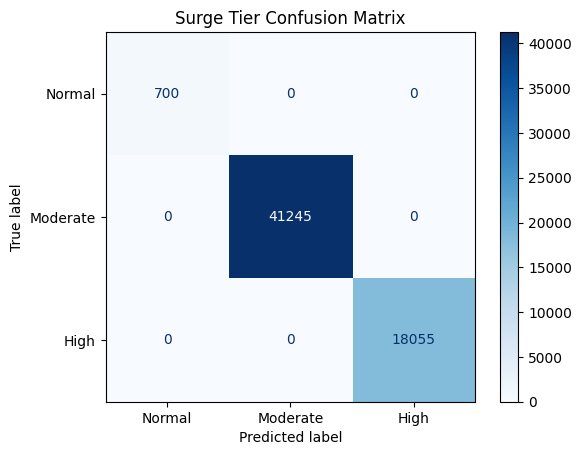

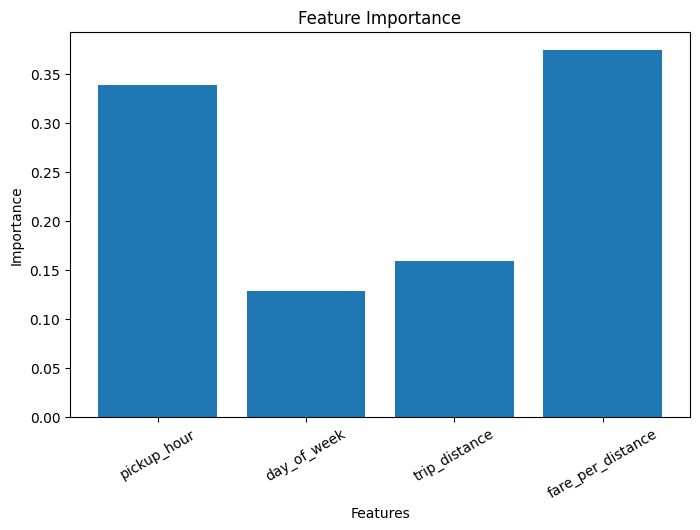

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay


ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=['Normal', 'Moderate', 'High'],
    cmap='Blues'
)

plt.title('Surge Tier Confusion Matrix')
plt.show()


importance = model.feature_importances_

plt.figure(figsize=(8, 5))
plt.bar(X.columns, importance)
plt.title('Feature Importance')
plt.xlabel('Features')
plt.ylabel('Importance')
plt.xticks(rotation=30)
plt.show()

pillar B

In [28]:
import pandas as pd
import numpy as np

sample_df['passenger_count'] = sample_df['passenger_count'].fillna(0)

peak_hours = (
    ((sample_df['pickup_hour'] >= 7) & (sample_df['pickup_hour'] <= 10)) |
    ((sample_df['pickup_hour'] >= 17) & (sample_df['pickup_hour'] <= 20))
)

sample_df['peak_idle_minutes'] = np.where(peak_hours, 10, 2)

sample_df['pickup_zone'] = (
    sample_df['pickup_latitude'].round(2).astype(str) + "_" +
    sample_df['pickup_longitude'].round(2).astype(str)
)

sample_df['dropoff_zone'] = (
    sample_df['dropoff_latitude'].round(2).astype(str) + "_" +
    sample_df['dropoff_longitude'].round(2).astype(str)
)

sample_df['zone_pair'] = (
    sample_df['pickup_zone'] + "_" + sample_df['dropoff_zone']
)

route_counts = sample_df['zone_pair'].value_counts()

sample_df['zone_pair_count'] = sample_df['zone_pair'].map(route_counts)

sample_df['zone_pair_weight'] = (
    np.log1p(sample_df['zone_pair_count']) /
    np.log1p(sample_df['zone_pair_count'].max())
)

sample_df['CEPI_Score'] = (
    0.4 * sample_df['passenger_count']
    + 0.35 * sample_df['peak_idle_minutes']
    + 0.25 * (10 * sample_df['zone_pair_weight'])
)

print(sample_df[[
    'passenger_count',
    'peak_idle_minutes',
    'zone_pair_weight',
    'CEPI_Score'
]].head(10))

print("\nCEPI Statistics:")
print(sample_df['CEPI_Score'].describe())

          passenger_count  peak_idle_minutes  zone_pair_weight  CEPI_Score
3801703                 1                  2          0.361508    2.003769
1620092                 1                 10          0.501870    5.154675
8460962                 1                 10          0.801577    5.903942
4339863                 1                  2          0.728038    2.920095
1143050                 1                 10          0.710970    5.677424
5426087                 1                  2          0.689101    2.822753
10900816                1                 10          0.689500    5.623751
7265011                 1                  2          0.766809    3.017022
404224                  1                  2          0.632544    2.681359
6345838                 1                  2          0.083645    1.309113

CEPI Statistics:
count    300000.000000
mean          4.025146
std           1.589680
min           0.909113
25%           2.759352
50%           3.457241
75%           5.563

In [29]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = sample_df[[
    'passenger_count',
    'peak_idle_minutes',
    'zone_pair_weight'
]]

y = sample_df['CEPI_Score']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model_b = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

model_b.fit(X_train, y_train)

y_pred = model_b.predict(X_test)

print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 0.0003902828538985136
RMSE: 0.004948091920282266
R2 Score: 0.9999903709157284


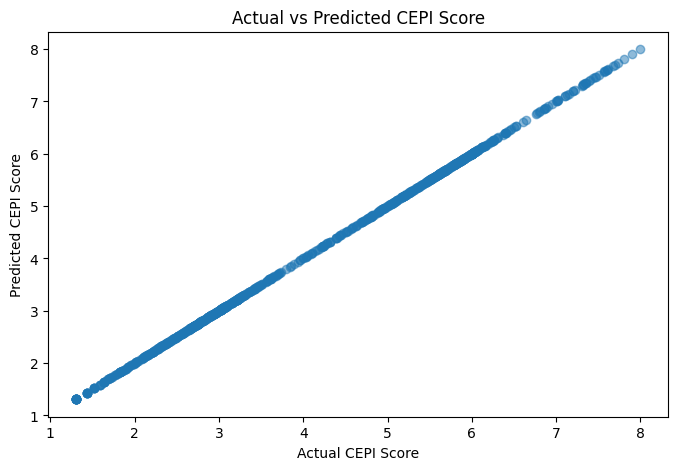

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(y_test[:1000], y_pred[:1000], alpha=0.5)
plt.xlabel("Actual CEPI Score")
plt.ylabel("Predicted CEPI Score")
plt.title("Actual vs Predicted CEPI Score")
plt.show()

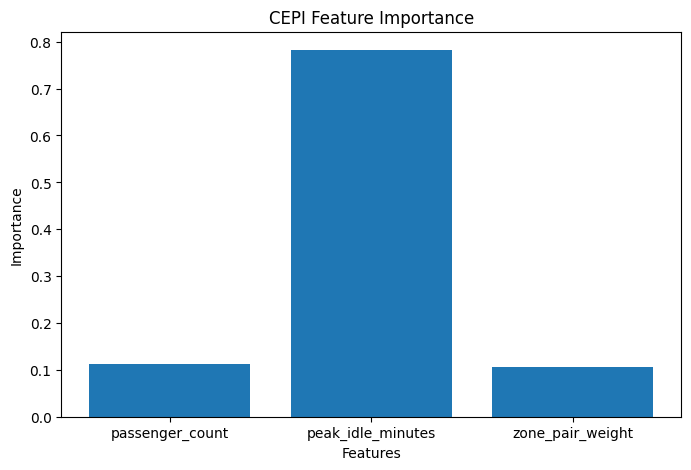

In [31]:
import matplotlib.pyplot as plt

importance = model_b.feature_importances_

plt.figure(figsize=(8, 5))
plt.bar(X.columns, importance)
plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("CEPI Feature Importance")
plt.show()

In [66]:
predictions = model_b.predict(X_test)

result = pd.DataFrame({
    'Actual_CEPI': y_test.values,
    'Predicted_CEPI': predictions
})

print(result.head(10))

   Actual_CEPI  Predicted_CEPI
0     4.231435        4.231435
1     6.249803        6.251008
2     2.231435        2.231435
3     2.520797        2.521377
4     4.812449        4.811375
5     5.627707        5.627320
6     2.605542        2.605324
7     1.431435        1.431435
8     2.964422        2.964458
9     5.312531        5.312264


Random Forest
RMSE: 0.004948091920282266
R2 Score: 0.9999903709157284
----------------------
Decision Tree
RMSE: 0.005029934925901161
R2 Score: 0.9999900497451839
----------------------
KNN
RMSE: 0.004810016423329138
R2 Score: 0.9999909008130453
----------------------
Linear Regression
RMSE: 1.4049005650703732e-15
R2 Score: 1.0
----------------------


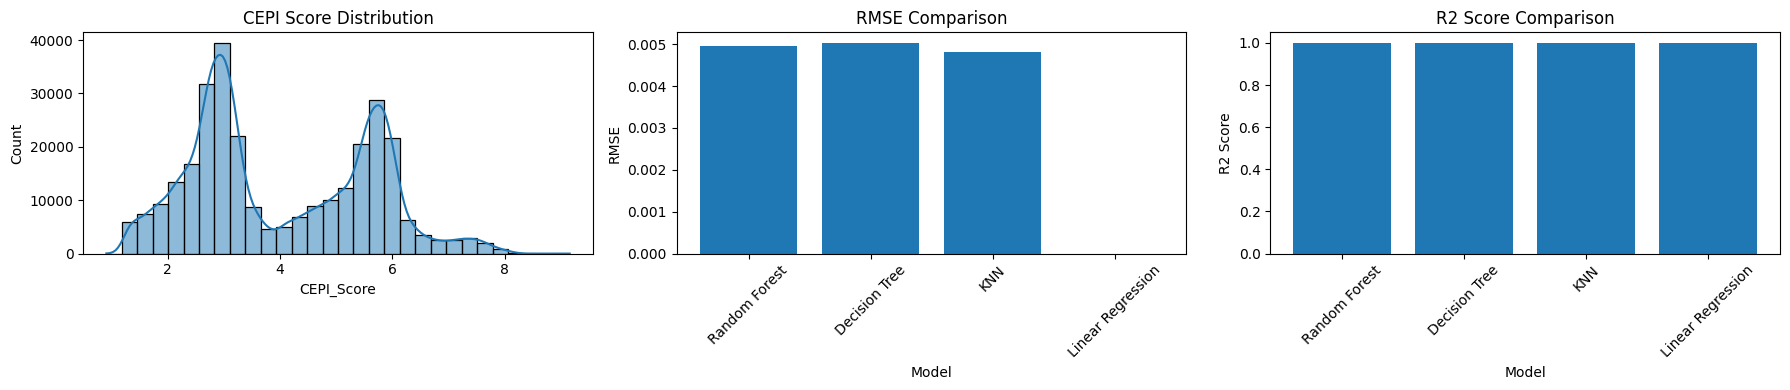

In [68]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=12,
        random_state=42,
        n_jobs=-1
    ),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=12,
        random_state=42
    ),
    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsRegressor(n_neighbors=5)
    ),
    "Linear Regression": make_pipeline(
        StandardScaler(),
        LinearRegression()
    )
}

rmse_values = []
r2_values = []
model_names = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    model_names.append(name)
    rmse_values.append(rmse)
    r2_values.append(r2)

    print(name)
    print("RMSE:", rmse)
    print("R2 Score:", r2)
    print("----------------------")

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

sns.histplot(
    sample_df['CEPI_Score'],
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("CEPI Score Distribution")
axes[0].set_xlabel("CEPI_Score")
axes[0].set_ylabel("Count")

axes[1].bar(model_names, rmse_values)
axes[1].set_title("RMSE Comparison")
axes[1].set_xlabel("Model")
axes[1].set_ylabel("RMSE")
axes[1].tick_params(axis='x', rotation=45)

axes[2].bar(model_names, r2_values)
axes[2].set_title("R2 Score Comparison")
axes[2].set_xlabel("Model")
axes[2].set_ylabel("R2 Score")
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


In [67]:
from sklearn.ensemble import RandomForestRegressor

model_b = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

model_b.fit(X_train, y_train)

print("Model training completed")

Model training completed


Pillar C

In [55]:
import os
import zipfile
import glob

folder = "/kaggle/input/datasets/rottelarakesh/nyc-taxi-zones-official-shapefile"

print(os.listdir(folder))

zip_file = glob.glob(folder + "/*.zip")[0]

extract_folder = "/kaggle/working/taxi_zones"

os.makedirs(extract_folder, exist_ok=True)

with zipfile.ZipFile(zip_file, "r") as z:
    z.extractall(extract_folder)

print("Extraction completed!")

['taxi_zones']


IndexError: list index out of range

In [57]:
import geopandas as gpd

shp_file = "/kaggle/input/datasets/rottelarakesh/nyc-taxi-zones-official-shapefile/taxi_zones/taxi_zones.shp"

zones = gpd.read_file(shp_file)

print(zones.columns.tolist())
print(zones.head())

['OBJECTID', 'Shape_Leng', 'Shape_Area', 'zone', 'LocationID', 'borough', 'geometry']
   OBJECTID  Shape_Leng  Shape_Area                     zone  LocationID  \
0         1    0.116357    0.000782           Newark Airport           1   
1         2    0.433470    0.004866              Jamaica Bay           2   
2         3    0.084341    0.000314  Allerton/Pelham Gardens           3   
3         4    0.043567    0.000112            Alphabet City           4   
4         5    0.092146    0.000498            Arden Heights           5   

         borough                                           geometry  
0            EWR  POLYGON ((933100.918 192536.086, 933091.011 19...  
1         Queens  MULTIPOLYGON (((1033269.244 172126.008, 103343...  
2          Bronx  POLYGON ((1026308.77 256767.698, 1026495.593 2...  
3      Manhattan  POLYGON ((992073.467 203714.076, 992068.667 20...  
4  Staten Island  POLYGON ((935843.31 144283.336, 936046.565 144...  


In [58]:
import pandas as pd
import numpy as np

zones = zones.to_crs("EPSG:4326")

sample_df = sample_df.copy()

sample_df = sample_df.dropna(subset=[
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude"
])

sample_df = sample_df[
    sample_df["pickup_longitude"].between(-75, -72) &
    sample_df["dropoff_longitude"].between(-75, -72) &
    sample_df["pickup_latitude"].between(39, 42) &
    sample_df["dropoff_latitude"].between(39, 42)
].copy()

pickup_points = gpd.GeoDataFrame(
    sample_df[["pickup_longitude", "pickup_latitude"]].copy(),
    geometry=gpd.points_from_xy(
        sample_df["pickup_longitude"],
        sample_df["pickup_latitude"]
    ),
    crs="EPSG:4326"
)

dropoff_points = gpd.GeoDataFrame(
    sample_df[["dropoff_longitude", "dropoff_latitude"]].copy(),
    geometry=gpd.points_from_xy(
        sample_df["dropoff_longitude"],
        sample_df["dropoff_latitude"]
    ),
    crs="EPSG:4326"
)

pickup_join = gpd.sjoin(
    pickup_points,
    zones[["LocationID", "geometry"]],
    how="left",
    predicate="within"
)

dropoff_join = gpd.sjoin(
    dropoff_points,
    zones[["LocationID", "geometry"]],
    how="left",
    predicate="within"
)

sample_df["PULocationID"] = pickup_join["LocationID"].values
sample_df["DOLocationID"] = dropoff_join["LocationID"].values

sample_df = sample_df.dropna(
    subset=["PULocationID", "DOLocationID"]
).copy()

sample_df["PULocationID"] = sample_df["PULocationID"].astype(int)
sample_df["DOLocationID"] = sample_df["DOLocationID"].astype(int)

print("Mapped taxi trips:", len(sample_df))
print(sample_df[["PULocationID", "DOLocationID"]].head(10))

Mapped taxi trips: 294117
          PULocationID  DOLocationID
3801703            238            74
1620092            132           230
8460962            142           161
4339863            230           236
1143050             90            48
5426087            249           231
10900816           170           141
7265011             79            79
404224             137           229
6345838            113            67


In [59]:
routes = sample_df.groupby(
    ['PULocationID', 'DOLocationID']
).size().reset_index(name='route_frequency')

routes['pickup_frequency'] = routes.groupby(
    'PULocationID'
)['route_frequency'].transform('sum')

routes['dropoff_frequency'] = routes.groupby(
    'DOLocationID'
)['route_frequency'].transform('sum')

print(routes.head(10))
print("Total unique routes:", len(routes))

   PULocationID  DOLocationID  route_frequency  pickup_frequency  \
0             1             1               12                13   
1             1           163                1                13   
2             4             4               36               914   
3             4             7                3               914   
4             4            13                2               914   
5             4            14                1               914   
6             4            17                2               914   
7             4            18                1               914   
8             4            25                3               914   
9             4            33                3               914   

   dropoff_frequency  
0                431  
1               7088  
2               1603  
3               1682  
4               2863  
5                283  
6                643  
7                 43  
8                595  
9                885 

In [60]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.cluster import MiniBatchKMeans
from scipy.sparse import hstack, csr_matrix
import numpy as np

encoder = OneHotEncoder(handle_unknown='ignore')

zone_features = encoder.fit_transform(
    routes[['PULocationID', 'DOLocationID']].astype(str)
)

frequency_features = np.log1p(
    routes[['route_frequency', 'pickup_frequency', 'dropoff_frequency']]
)

scaler = StandardScaler()
frequency_scaled = scaler.fit_transform(frequency_features)

X_cluster = hstack([
    zone_features,
    csr_matrix(frequency_scaled)
])

kmeans = MiniBatchKMeans(
    n_clusters=5,
    random_state=42,
    batch_size=1024,
    n_init=10
)

routes['Ghost_Corridor'] = kmeans.fit_predict(X_cluster)

print(routes.head(10))

print("\nCluster Distribution:")
print(routes['Ghost_Corridor'].value_counts().sort_index())

   PULocationID  DOLocationID  route_frequency  pickup_frequency  \
0             1             1               12                13   
1             1           163                1                13   
2             4             4               36               914   
3             4             7                3               914   
4             4            13                2               914   
5             4            14                1               914   
6             4            17                2               914   
7             4            18                1               914   
8             4            25                3               914   
9             4            33                3               914   

   dropoff_frequency  Ghost_Corridor  
0                431               4  
1               7088               2  
2               1603               0  
3               1682               2  
4               2863               2  
5                

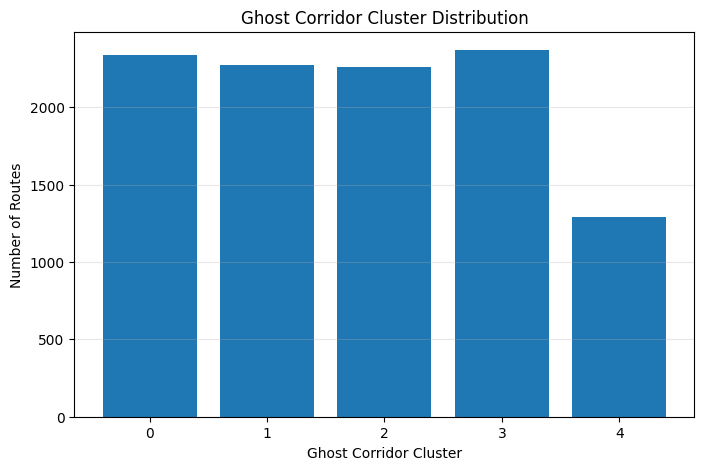

In [61]:
import matplotlib.pyplot as plt

cluster_counts = routes['Ghost_Corridor'].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(cluster_counts.index, cluster_counts.values)
plt.xlabel('Ghost Corridor Cluster')
plt.ylabel('Number of Routes')
plt.title('Ghost Corridor Cluster Distribution')
plt.xticks(range(5))
plt.grid(axis='y', alpha=0.3)
plt.show()

In [62]:
for cluster in sorted(routes['Ghost_Corridor'].unique()):
    print("\nGhost Corridor Cluster:", cluster)

    result = routes[routes['Ghost_Corridor'] == cluster]

    print(
        result.sort_values(
            'route_frequency', ascending=False
        ).head(5)
    )


Ghost Corridor Cluster: 0
      PULocationID  DOLocationID  route_frequency  pickup_frequency  \
9265           237           236             1486             11230   
9134           236           237             1360             10659   
9133           236           236             1319             10659   
9266           237           237             1167             11230   
9498           239           238              853              7601   

      dropoff_frequency  Ghost_Corridor  
9265              10644               0  
9134               9772               0  
9133              10644               0  
9266               9772               0  
9498               5909               0  

Ghost Corridor Cluster: 1
      PULocationID  DOLocationID  route_frequency  pickup_frequency  \
4155           132            10               53              6755   
5867           152           152               46               283   
4331           132           216               43     

In [63]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

sample_size = min(2000, X_cluster.shape[0])

sil_score = silhouette_score(
    X_cluster,
    routes['Ghost_Corridor'],
    sample_size=sample_size,
    random_state=42
)

db_score = davies_bouldin_score(
    X_cluster.toarray(),
    routes['Ghost_Corridor']
)

print("Silhouette Score:", sil_score)
print("Davies-Bouldin Score:", db_score)

Silhouette Score: 0.14731491234390934
Davies-Bouldin Score: 1.9298957033737403


In [64]:
print(zones.columns.tolist())

['OBJECTID', 'Shape_Leng', 'Shape_Area', 'zone', 'LocationID', 'borough', 'geometry']


In [65]:
print(zones[['LocationID', 'borough', 'zone']].head())

   LocationID        borough                     zone
0           1            EWR           Newark Airport
1           2         Queens              Jamaica Bay
2           3          Bronx  Allerton/Pelham Gardens
3           4      Manhattan            Alphabet City
4           5  Staten Island            Arden Heights


In [69]:
zone_names = zones[['LocationID', 'borough', 'zone']].drop_duplicates()

routes_named = routes.merge(
    zone_names.rename(columns={
        'LocationID': 'PULocationID',
        'borough': 'Pickup_Borough',
        'zone': 'Pickup_Zone'
    }),
    on='PULocationID',
    how='left'
)

routes_named = routes_named.merge(
    zone_names.rename(columns={
        'LocationID': 'DOLocationID',
        'borough': 'Dropoff_Borough',
        'zone': 'Dropoff_Zone'
    }),
    on='DOLocationID',
    how='left'
)

print(routes_named[[
    'PULocationID',
    'Pickup_Zone',
    'DOLocationID',
    'Dropoff_Zone',
    'route_frequency',
    'Ghost_Corridor'
]].head(10))

   PULocationID     Pickup_Zone  DOLocationID       Dropoff_Zone  \
0             1  Newark Airport             1     Newark Airport   
1             1  Newark Airport           163      Midtown North   
2             4   Alphabet City             4      Alphabet City   
3             4   Alphabet City             7            Astoria   
4             4   Alphabet City            13  Battery Park City   
5             4   Alphabet City            14          Bay Ridge   
6             4   Alphabet City            17            Bedford   
7             4   Alphabet City            18       Bedford Park   
8             4   Alphabet City            25        Boerum Hill   
9             4   Alphabet City            33   Brooklyn Heights   

   route_frequency  Ghost_Corridor  
0               12               4  
1                1               2  
2               36               0  
3                3               2  
4                2               2  
5                1           

In [70]:
for cluster in sorted(routes_named['Ghost_Corridor'].unique()):
    print("\nGHOST CORRIDOR CLUSTER:", cluster)

    result = routes_named[
        routes_named['Ghost_Corridor'] == cluster
    ]

    print(
        result.sort_values(
            'route_frequency',
            ascending=False
        )[[
            'Pickup_Borough',
            'Pickup_Zone',
            'Dropoff_Borough',
            'Dropoff_Zone',
            'route_frequency'
        ]].head(5)
    )


GHOST CORRIDOR CLUSTER: 0
     Pickup_Borough            Pickup_Zone Dropoff_Borough  \
9265      Manhattan  Upper East Side South       Manhattan   
9134      Manhattan  Upper East Side North       Manhattan   
9133      Manhattan  Upper East Side North       Manhattan   
9266      Manhattan  Upper East Side South       Manhattan   
9498      Manhattan  Upper West Side South       Manhattan   

               Dropoff_Zone  route_frequency  
9265  Upper East Side North             1486  
9134  Upper East Side South             1360  
9133  Upper East Side North             1319  
9266  Upper East Side South             1167  
9498  Upper West Side North              853  

GHOST CORRIDOR CLUSTER: 1
     Pickup_Borough      Pickup_Zone Dropoff_Borough      Dropoff_Zone  \
4155         Queens      JFK Airport          Queens      Baisley Park   
5867      Manhattan   Manhattanville       Manhattan    Manhattanville   
4331         Queens      JFK Airport          Queens  South Ozone Par

In [71]:
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.preprocessing import StandardScaler
import numpy as np

sample_size = min(2000, X_cluster.shape[0])

sil_score = silhouette_score(
    X_cluster,
    routes['Ghost_Corridor'],
    sample_size=sample_size,
    random_state=42
)

X_dense = X_cluster.toarray()

db_score = davies_bouldin_score(
    X_dense,
    routes['Ghost_Corridor']
)

print("Silhouette Score:", sil_score)
print("Davies-Bouldin Score:", db_score)

Silhouette Score: 0.14731491234390934
Davies-Bouldin Score: 1.9298957033737403
